# Minimal axisymmetric inductor example
This notebook builds the same 14-turn inductor as `example_inductor.ipynb`, but uses only the high-level constructor API. All lengths are in metres.

In [ ]:
from dataclasses import asdict
import json
from pathlib import Path
import sys

repository_root = Path.cwd().resolve()
if not (repository_root / "model").is_dir():
    repository_root = repository_root.parent
if str(repository_root) not in sys.path:
    sys.path.insert(0, str(repository_root))

import matplotlib.pyplot as plt
from model import (
    AirGapSpec,
    Constructor,
    CoreSpec,
    InsulationSpec,
    Material,
    RoundConductor,
)
from fem import (
    COPPER_CONDUCTIVITY_AT_20C_S_PER_M,
    PhysicalField,
    FrequencyDomainSimulation,
    plot_mesh,
)

## 1. Describe the component

The constructor places two conductor columns and seven axial rows, giving 14 turns.

In [ ]:
frequency_hz = 900_000.0
current_a = 4.5

core = CoreSpec(
    name="core",
    material="core",
    outer_radius=0.019943733351606967,
    outer_half_height=0.018475,
    window_inner_radius=0.00745,
    window_outer_radius=0.0185,
    window_half_height=0.01475,
    core_type="Single",
)
conductor = RoundConductor(
    name="round_copper",
    radius=0.0013,
    material="copper",
)
insulation = InsulationSpec(
    c2w_left=0.003,
    c2w_right=0.00235,
    c2w_top=0.0073,
    c2w_bottom=0.001,
    w2w=0.0005,
)
primary = Constructor.place_winding(
    core=core,
    insulation=insulation,
    name="primary",
    conductor=conductor,
    circuit="primary",
    turns=14,
    radial_columns=2,
    current=current_a,
)
model = Constructor(
    core=core,
    windings=(primary,),
    air_gaps=(AirGapSpec("center_gap", 0.003725, 0.0, 0.00745, 0.0005),),
    insulation=insulation,
    metadata={"name": "minimal example inductor"},
).build()
model.materials = [
    Material("core", 
             relative_permeability=1500.0, 
             permeability_loss_angle_deg=5.0,
             conductivity=0.6, 
             relative_permittivity=100_000.0,
             permittivity_loss_angle_deg=25.0),
    Material("air"),
    Material("copper", conductivity=COPPER_CONDUCTIVITY_AT_20C_S_PER_M),
]
model.excitation.frequency = frequency_hz
model.excitation.circuits = {"primary": current_a}

simulation_dir = repository_root / "notebooks" / "sim"
simulation_dir.mkdir(exist_ok=True)
constructor_json = simulation_dir / "minimal_inductor.json"
model_data = asdict(model)
model_data.pop("_legacy", None)
constructor_json.write_text(json.dumps(model_data, indent=2) + "\n", encoding="utf-8")
print(f"Saved constructor: {constructor_json}")

Saved constructor: C:\Users\tpiepe\Repositories\pyMagFEM\notebooks\sim\minimal_inductor.json


## 2. Mesh and solve

The mesh is coarse in the bulk and adapts around the core corners, air gap, and solid conductor surface.

In [3]:
simulation = FrequencyDomainSimulation(model)
mesh = simulation.create_mesh()
result = simulation.solve()


## 3. Post processing

The result object keeps the solved fields and provides coordinated post-processing without repeating mesh or material arguments.

In [4]:
a_phi = result.a_phi
current_densities = result.current_densities
flux_density = result.magnetic_flux_density()
field_intensity = result.magnetic_field_intensity()


## 4. Standard report

The report contains the model, mesh, conductor, loss, voltage, inductance, and field results. It can be reused for larger transformer examples.

In [5]:
report = result.report()
report.print()
result_json = simulation_dir / "minimal_inductor_result.json"
report.write_json(result_json)
print(f"Saved result: {result_json}")


Frequency: 900,000 Hz
Current primary: 4.500 A
Mesh: 1605 nodes, 3098 triangles
Average |J| conductor_0: 9.535e+06 A/m²
Maximum |J| conductor_0: 2.210e+07 A/m²
Current constraint error conductor_0: 1.217e-10 A
Average |J| conductor_1: 4.895e+06 A/m²
Maximum |J| conductor_1: 1.080e+07 A/m²
Current constraint error conductor_1: 2.282e-11 A
Average |J| conductor_2: 5.654e+06 A/m²
Maximum |J| conductor_2: 1.123e+07 A/m²
Current constraint error conductor_2: 2.759e-11 A
Average |J| conductor_3: 1.058e+07 A/m²
Maximum |J| conductor_3: 2.207e+07 A/m²
Current constraint error conductor_3: 3.430e-11 A
Average |J| conductor_4: 1.233e+07 A/m²
Maximum |J| conductor_4: 2.590e+07 A/m²
Current constraint error conductor_4: 1.006e-09 A
Average |J| conductor_5: 6.547e+06 A/m²
Maximum |J| conductor_5: 1.449e+07 A/m²
Current constraint error conductor_5: 3.173e-11 A
Average |J| conductor_6: 6.994e+06 A/m²
Maximum |J| conductor_6: 1.778e+07 A/m²
Current constraint error conductor_6: 1.001e-09 A
Average |J

## 5. Plot the result

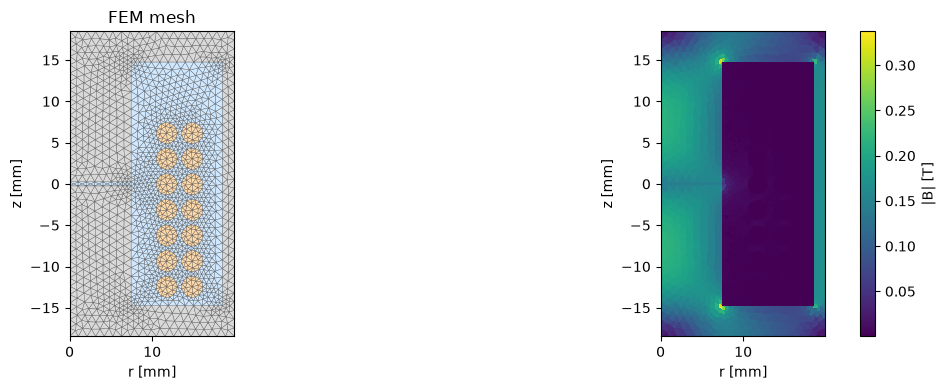

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_mesh(mesh, ax=axes[0])
result.plot_physical_field(PhysicalField.B, ax=axes[1])
# result.plot_physical_field(PhysicalField.H, ax=axes[1])
# result.plot_physical_field(PhysicalField.J, ax=axes[1])
# result.plot_physical_field(PhysicalField.E, ax=axes[1])
# result.plot_physical_field(PhysicalField.MU, ax=axes[1])
# result.plot_physical_field(PhysicalField.MU_REAL, ax=axes[1])
# result.plot_physical_field(PhysicalField.MU_IMAG, ax=axes[1])
# result.plot_physical_field(PhysicalField.LOSS_DENSITY, ax=axes[1])
# result.plot_physical_field(PhysicalField.MAG_LOSS_DENSITY, ax=axes[1])
# result.plot_physical_field(PhysicalField.ELECTRIC_LOSS_DENSITY, ax=axes[1])
plt.tight_layout()
plt.show()
